# Defect Detection with PatchCore (Real-IAD) - one model per view

## 1. Settings

In [4]:
import json, os, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image

category = "audiojack"   # change this for each product
views = ["C1", "C2", "C3", "C4", "C5"]
max_train = 400          # lower it if you get CUDA out of memory

base = os.path.expanduser("~/Real-IAD/realiad_512")
img_dir = os.path.join(base, category)
json_path = os.path.join(base, "JSON", "realiad_jsons", category + ".json")
out = os.path.expanduser("~/prepared_" + category)   # the prepared folders

# use the GPU if PyTorch can see it
if torch.cuda.is_available():
    device = "cuda"
else:
    device = "cpu"

print(device, os.path.exists(json_path), os.path.exists(img_dir))

cuda True True


## 2. Load the JSON
The JSON says which images are for train (normal only) and which are for test.

In [5]:
f = open(json_path)
data = json.load(f)
f.close()

print("train:", len(data["train"]), "test:", len(data["test"]))

train: 1235 test: 3815


## 3. Sort the images into folders for each view

In [6]:
# start from empty folders
if os.path.exists(out):
    shutil.rmtree(out)

for view in views:
    os.makedirs(os.path.join(out, view, "train_good"))
    os.makedirs(os.path.join(out, view, "test_good"))
    os.makedirs(os.path.join(out, view, "test_bad"))

    # normal training images of this view
    count = 0
    for item in data["train"]:
        if "_" + view + "_" in item["image_path"] and count < max_train:
            shutil.copy(os.path.join(img_dir, item["image_path"]), os.path.join(out, view, "train_good"))
            count = count + 1

    # test images of this view: OK = normal, anything else = defective
    for item in data["test"]:
        if "_" + view + "_" in item["image_path"]:
            if item["anomaly_class"] == "OK":
                folder = "test_good"
            else:
                folder = "test_bad"
            shutil.copy(os.path.join(img_dir, item["image_path"]), os.path.join(out, view, folder))

    print(view, len(os.listdir(os.path.join(out, view, "train_good"))),
          len(os.listdir(os.path.join(out, view, "test_good"))),
          len(os.listdir(os.path.join(out, view, "test_bad"))))

C1 247 550 213
C2 247 477 286
C3 247 518 245
C4 247 489 274
C5 247 485 278


## 4. Train one PatchCore for each view

In [7]:
from anomalib.data import Folder
from anomalib.models import Patchcore
from anomalib.engine import Engine

patchcore_models = {}
patchcore_engines = {}

scores = []
labels = []
paths = []
test_views = []

for view in views:
    print("Training", view)

    datamodule = Folder(
        name=category + "_" + view,
        root=os.path.join(out, view),
        normal_dir="train_good",
        normal_test_dir="test_good",
        abnormal_dir="test_bad",
        train_batch_size=32,
        eval_batch_size=32,
        num_workers=0,
    )

    model = Patchcore()
    # progress bar off: the Rich bar crashes inside Jupyter
    engine = Engine(accelerator="auto", devices=1, enable_progress_bar=False)

    engine.fit(model=model, datamodule=datamodule)
    engine.test(model=model, datamodule=datamodule)

    # score of every test image of this view
    predictions = engine.predict(model=model, dataloaders=datamodule.test_dataloader())
    for batch in predictions:
        for s in batch.pred_score:
            scores.append(float(s))
        for l in batch.gt_label:
            labels.append(int(l))
        for p in batch.image_path:
            paths.append(p)
            test_views.append(view)

    patchcore_models[view] = model
    patchcore_engines[view] = engine
    torch.cuda.empty_cache()   # free GPU memory

/home/ali/venv/lib/python3.12/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/home/ali/venv/lib/python3.12/site-packages/anomalib/models/image/dinomaly/components/layers.py:22: FutureWarning: The anomalib.models.components.dinov2 package is deprecated and will be removed in a future release. Please use the timm-based feature extractor instead: anomalib.models.components.feature_extractors.TimmFeatureExtractor
  from anomalib.models.components.dinov2.layers import Attention, DropPath, LayerScale, MemEffAttention


Training C1


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA GeForce RTX 4060') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/home/ali/venv/lib/python3.12/site-packages/lightning/pytorch/core/optimizer.py:183: `LightningModule.configure_optimizers` returned `None`, this fit will run with no optimizer


┏━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name           ┃ Type           ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ pre_processor  │ PreProcessor   │      0 │ train │     0 │
│ 1 │ post_processor │ PostProcessor  │      0 │ train │     0 │
│ 2 │ evaluator      │ Evaluator      │      0 │ train │     0 │
│ 3 │ model          │ PatchcoreModel │ 24.9 M │ train │     0 │
└───┴────────────────┴────────────────┴────────┴───────┴───────┘

Trainable params: 24.9 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 24.9 M                                                                                               
Total estimated model params size (MB): 99.450                                                                     
Modules in train mode: 19                                                                                          
Modules in eval mode: 174                                                                                          
Total FLOPs: 0

/home/ali/venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/home/ali/venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.
/home/ali/venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.
/home/ali/venv/lib/python3.12/site-packages/lightning/pytorch/loops/fit_loop.py:538: Found 174 module(s) in eval mode at the start of training. This may lead to unexpected behavior durin

... (26 outputs left out)

Trainable params: 24.9 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 24.9 M                                                                                               
Total estimated model params size (MB): 99.450                                                                     
Modules in train mode: 19                                                                                          
Modules in eval mode: 174                                                                                          
Total FLOPs: 0

/home/ali/venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/home/ali/venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.
/home/ali/venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.
/home/ali/venv/lib/python3.12/site-packages/lightning/pytorch/loops/fit_loop.py:538: Found 174 module(s) in eval mode at the start of training. This may lead to unexpected behavior durin

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│        image_AUROC        │    0.8426148295402527     │
│       image_F1Score       │    0.6909090876579285     │
└───────────────────────────┴───────────────────────────┘

ckpt_path is not provided. Model weights will not be loaded.
The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, ImageVisualizer, PostProcessor, PreProcessor
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/home/ali/venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


## 5. Evaluate: normal or defective

In [14]:
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report , ConfusionMatrixDisplay , RocCurveDisplay

df = pd.DataFrame({"path": paths, "score": scores, "label": labels, "view": test_views})
df["pred"] = 0
thresholds = {}

for view in views:
    part = df[df["view"] == view]
    print(view, "AUROC:", roc_auc_score(part["label"], part["score"]))

    # best threshold = where (true positives - false positives) is highest
    fpr, tpr, thr = roc_curve(part["label"], part["score"])
    best = (tpr - fpr).argmax()
    thresholds[view] = thr[best]
    df.loc[df["view"] == view, "pred"] = (part["score"] >= thr[best]).astype(int)

C1 AUROC: 0.8306032285471536
C2 AUROC: 0.8178307048599935
C3 AUROC: 0.9015287064067551
C4 AUROC: 0.8475197378221361
C5 AUROC: 0.8426147970512479


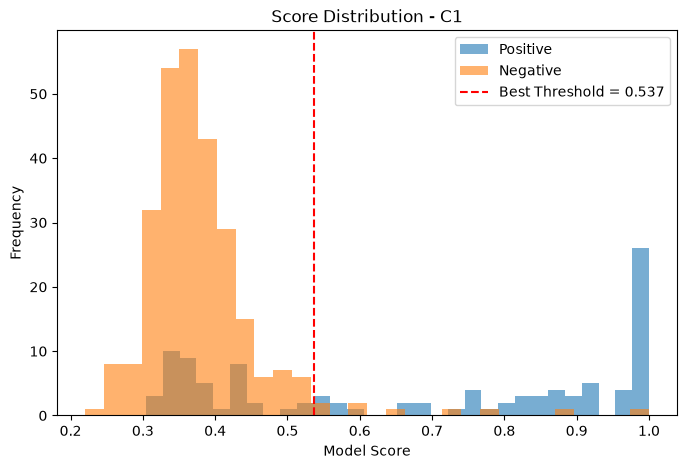

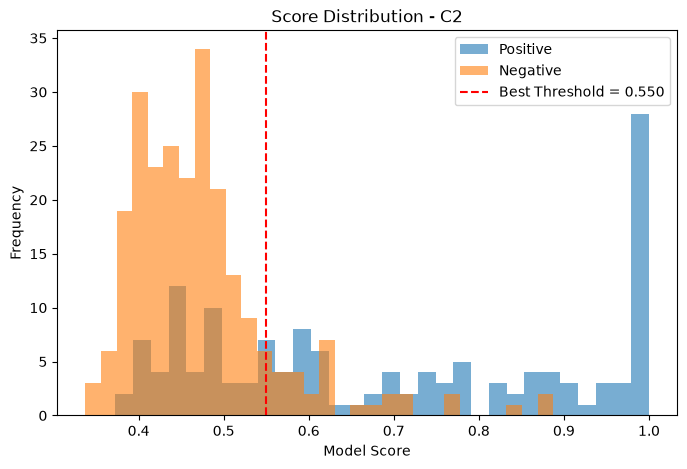

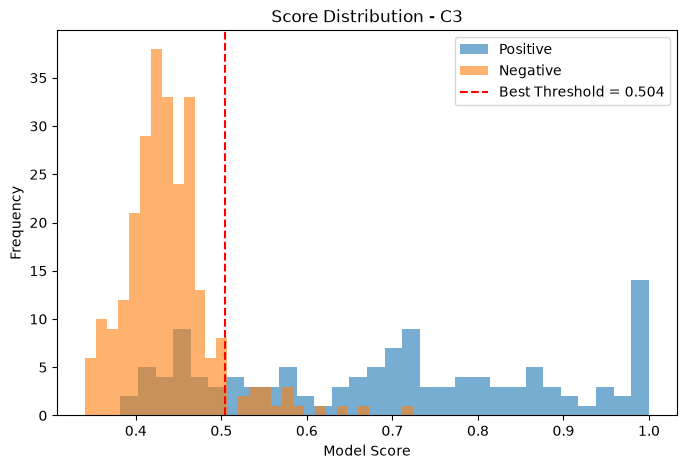

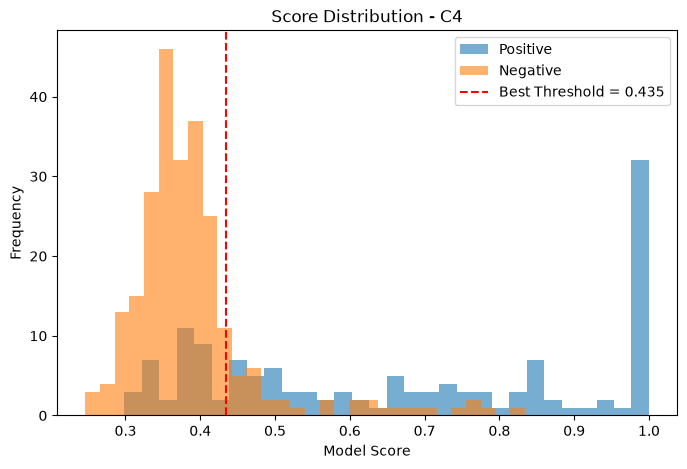

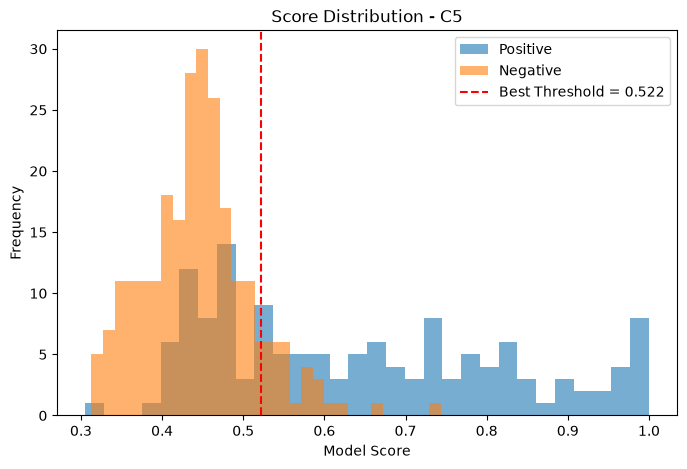

In [18]:
for view in views:
    part = df[df["view"] == view]

    threshold = thresholds[view]

    plt.figure(figsize=(8, 5))

    plt.hist(part[part["label"] == 1]["score"],
             bins=30, alpha=0.6, label="Positive")

    plt.hist(part[part["label"] == 0]["score"],
             bins=30, alpha=0.6, label="Negative")

    plt.axvline(threshold, color="red", linestyle="--",
                label=f"Best Threshold = {threshold:.3f}")

    plt.title(f"Score Distribution - {view}")
    plt.xlabel("Model Score")
    plt.ylabel("Frequency")
    plt.legend()
    plt.show()

              precision    recall  f1-score   support

           0       0.86      0.91      0.88      1261
           1       0.80      0.70      0.75       649

    accuracy                           0.84      1910
   macro avg       0.83      0.81      0.82      1910
weighted avg       0.84      0.84      0.84      1910



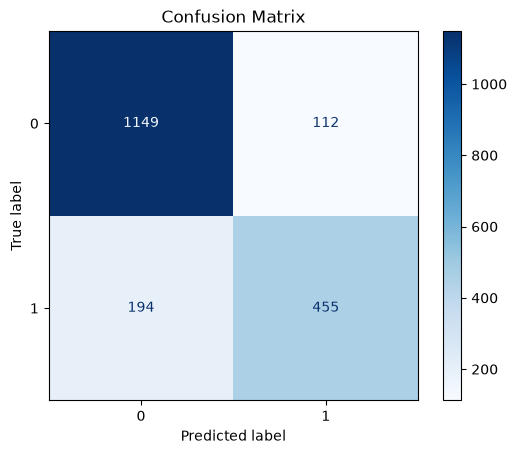

In [11]:
print(classification_report(df["label"], df["pred"]))

ConfusionMatrixDisplay.from_predictions(
    df["label"],
    df["pred"],
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.show()

## 6. Detect a defect on one image
One function: it reads the view from the file name, gives normal or defective, and shows the heatmap.

ckpt_path is not provided. Model weights will not be loaded.
The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, ImageVisualizer, PostProcessor, PreProcessor
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/home/ali/venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/home/ali/venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


C1 DEFECTIVE - score: 0.766


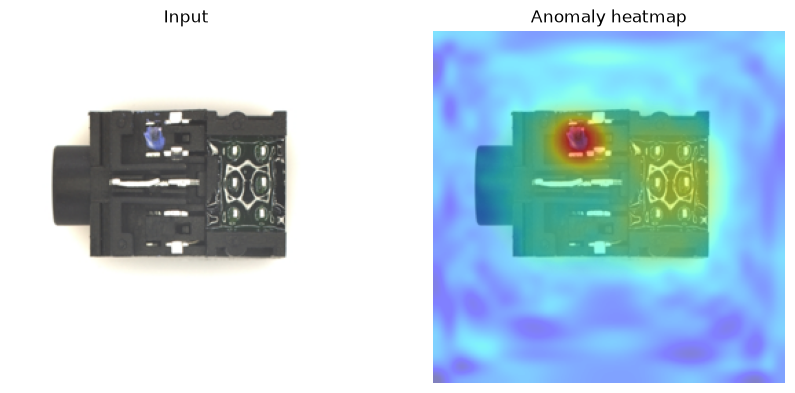

In [10]:
def detect(file):
    # the view (C1 to C5) is in the file name
    for v in views:
        if "_" + v + "_" in file:
            view = v

    # PatchCore of this view gives the score and the heatmap
    result = patchcore_engines[view].predict(model=patchcore_models[view], data_path=file)
    score = float(result[0].pred_score)
    amap = result[0].anomaly_map.squeeze().cpu().numpy()

    # normal or defective, using the threshold of this view
    if score >= thresholds[view]:
        print(view, "DEFECTIVE - score:", round(score, 3))
    else:
        print(view, "NORMAL - score:", round(score, 3))

    # the heatmap has a smaller size, so resize the image to match it
    img = Image.open(file).convert("RGB").resize((amap.shape[1], amap.shape[0]))

    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.title("Input")
    plt.axis("off")
    plt.subplot(1, 2, 2)
    plt.imshow(img)
    plt.imshow(amap, cmap="jet", alpha=0.5)   # red = where the defect is
    plt.title("Anomaly heatmap")
    plt.axis("off")
    plt.show()


# try it on one defective image of C1
folder = os.path.join(out, "C1", "test_bad")
detect(os.path.join(folder, os.listdir(folder)[0]))

## 7. Save the models for Streamlit

In [20]:
save_dir = os.path.expanduser("~/models_" + category)
os.makedirs(save_dir, exist_ok=True)

# 1. PatchCore of each view
for view in views:
    patchcore_engines[view].trainer.save_checkpoint(os.path.join(save_dir, "patchcore_" + view + ".ckpt"))

# 2. thresholds (numpy numbers to normal floats)
thr_save = {}
for view in views:
    thr_save[view] = float(thresholds[view])

f = open(os.path.join(save_dir, "thresholds.json"), "w")
json.dump(thr_save, f)
f.close()

# check the files and their size
for name in os.listdir(save_dir):
    print(name, round(os.path.getsize(os.path.join(save_dir, name)) / 1000000), "MB")

`weights_only` was not set, defaulting to `False`.
`weights_only` was not set, defaulting to `False`.
`weights_only` was not set, defaulting to `False`.
`weights_only` was not set, defaulting to `False`.
`weights_only` was not set, defaulting to `False`.


patchcore_C3.ckpt 255 MB
patchcore_C2.ckpt 255 MB
thresholds.json 0 MB
patchcore_C5.ckpt 255 MB
patchcore_C1.ckpt 255 MB
patchcore_C4.ckpt 255 MB
